## Checkpoint

In [43]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "grafsainsdata")

def add_friend(driver, name, friend_name):
    driver.execute_query(
    "MERGE (a:Person {name: $name}) "
    "MERGE (friend:Person {name: $friend_name}) "
    "MERGE (a)-[:KNOWS]->(friend)",
    name=name, friend_name=friend_name, database_="utsgraf",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
    "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
    "RETURN friend.name ORDER BY friend.name",
    name=name, database_="utsgraf", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Checkpoint

1. Apa nama database yang digunakan pada tutorial ini?
neo4j, namun di kode saya, saya memakai database utsgraf

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
Menggunakan Klausa (query cypher), menggunakan Composite Database untuk menggabungkan beberapa database terpisah

3. Apa jenis graf pertemanan yang telah dibuat di sini?
Graf yang dibuat pada kode tersebut adalah Graf Berarah (Directed Graph) berjenis Homogen (Unipartite Graph)


## UTS Graf Sains Data

In [1]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", "grafsainsdata"))
session = driver.session(database="grafuts")



In [2]:
import pandas as pd

csv_file_path = r"D:\\Sains Data smt 7\\Graf Sains Data\\UTS Graf\\dataset_ecommerce\\events.csv"
total_rows = sum(1 for _ in open(csv_file_path)) - 1 
print(f"Total baris data: {total_rows}")

Total baris data: 2756101


In [3]:
import pandas as pd

csv_file_path = r"D:\\Sains Data smt 7\\Graf Sains Data\\UTS Graf\\dataset_ecommerce\\events.csv"

df = pd.read_csv(csv_file_path, usecols=['timestamp', 'event'])

df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

min_date = df['datetime'].min()
max_date = df['datetime'].max()

print(f"Tanggal Awal  : {min_date}")
print(f"Tanggal Akhir : {max_date}")


Tanggal Awal  : 2015-05-03 03:00:04.384000
Tanggal Akhir : 2015-09-18 02:59:47.788000


In [ ]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

In [5]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [6]:
from tqdm import tqdm

csv_file_path = "D:\\Sains Data smt 7\\Graf Sains Data\\UTS Graf\\dataset_ecommerce\\events.csv"

batch_size = 10000

with driver.session(database='grafuts') as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = 2756101
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
        ):

        chunk["transactionid"]=(
        chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

#driver.close()
print("Proses impor berhasil.")

Membaca file data dari: D:\Sains Data smt 7\Graf Sains Data\UTS Graf\dataset_ecommerce\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [11:51<00:00,  2.58s/it]

Proses impor berhasil.


## 2.1 Wrangling dan EDA

### Nomor 1

Tentukan 2 periode waktu sebagai filter dari data interaksi.

Jawaban: 
Fold Training (P1) = 7 - 20 Agustus 2015 ;
Fold Testing (P2) = 21 - 27 Agustus 2015

### Nomor 2

Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv

In [7]:
import pandas as pd
import os
import numpy as np

csv_file_path = r"D:\\Sains Data smt 7\\Graf Sains Data\\UTS Graf\\dataset_ecommerce\\events.csv"
df = pd.read_csv(csv_file_path)

df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

p1 = (df['datetime'] >= "2015-08-07") & (df['datetime'] < "2015-08-21")
p2 = (df['datetime'] >= "2015-08-21") & (df['datetime'] < "2015-08-28")

df_filtered = df[p1 | p2].copy()
df_filtered['period'] = np.where(p1[p1 | p2], 'P1', 'P2')
df_filtered = df_filtered.drop(columns=['datetime'])

output_csv = r"D:\\Sains Data smt 7\\Graf Sains Data\\UTS Graf\\dataset_ecommerce\\events_filtered.csv"
df_filtered.to_csv(output_csv, index=False)

print(f"Jumlah data terfilter: {len(df_filtered)} baris.")

Jumlah data terfilter: 369972 baris.


Memfilter data sesuai dengan P1 dan P2 yang telah dibuat, kemudia import ulang di database grafuts

In [8]:
# hapus bertahap (aman untuk jutaan relasi)
with driver.session(database='grafuts') as s:
    s.run("MATCH (n) CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS")

events_filtered di import di neo4j

In [45]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", "grafsainsdata"))
session = driver.session(database='grafuts')

In [10]:
def create_constraints(session):
    # Membuat constraint unik agar pencarian node cepat dan mencegah duplikasi
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

In [11]:
def import_batch(tx, records):
    query = """
    UNWIND $records AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp, period: row.period}]->(i)
    )
    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, period: row.period}]->(i)
    )
    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, period: row.period,
                             transactionId: row.transactionid}]->(i)
    )
    """
    tx.run(query, records=records)

In [12]:
from tqdm import tqdm
import pandas as pd

csv_file_path = r"D:\\Sains Data smt 7\\Graf Sains Data\\UTS Graf\\dataset_ecommerce\\events_filtered.csv"

batch_size = 10000

with driver.session(database='grafuts') as session:
    create_constraints(session)

    total_rows = sum(1 for _ in open(csv_file_path)) - 1
    total_chunks = (total_rows // batch_size) + 1
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = (
            chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 37/37 [01:23<00:00,  2.25s/it]

Proses impor berhasil.


In [13]:
with driver.session(database='grafuts') as s:
    print(s.run("MATCH ()-[r]->() RETURN count(r) AS n").single()["n"])

369972


### Nomor 3 

Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [47]:
query_simpul = """
MATCH (n)
RETURN labels(n)[0] AS JenisSimpul, count(n) AS JumlahSimpul
"""

with driver.session(database='grafuts') as session:
    result = session.run(query_simpul)
    for record in result:
        print(f"Jenis Simpul: {record['JenisSimpul']} | Jumlah: {record['JumlahSimpul']}")

Jenis Simpul: Visitor | Jumlah: 210737
Jenis Simpul: Item | Jumlah: 91927


In [48]:
query_relasi = """
MATCH ()-[r]->()
RETURN type(r) AS JenisRelasi, count(r) AS Jumlah
ORDER BY Jumlah DESC
"""

with driver.session(database='grafuts') as session:
    result = session.run(query_relasi)
    for record in result:
        print(f"Jenis Simpul: {record['JenisRelasi']} | Jumlah: {record['Jumlah']}")

Jenis Simpul: VIEWED | Jumlah: 357031
Jenis Simpul: ADDED_TO_CART | Jumlah: 9814
Jenis Simpul: BOUGHT | Jumlah: 3127
Jenis Simpul: SIMILAR_TO | Jumlah: 5


In [50]:
type_relasi = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS Dari, type(r) AS Relasi, labels(b)[0] AS Ke, count(*) AS Jumlah
ORDER BY Jumlah DESC
"""

with driver.session(database='grafuts') as session:
    result = session.run(type_relasi)
    for record in result:
        print(f"(:{record['Dari']})-[:{record['Relasi']}]->(:{record['Ke']}) | Jumlah: {record['Jumlah']}")

(:Visitor)-[:VIEWED]->(:Item) | Jumlah: 357031
(:Visitor)-[:ADDED_TO_CART]->(:Item) | Jumlah: 9814
(:Visitor)-[:BOUGHT]->(:Item) | Jumlah: 3127
(:Item)-[:SIMILAR_TO]->(:Item) | Jumlah: 5


Cypher SQL yang digunakan adalah:

MATCH (n): Mengambil seluruh simpul n yang ada di dalam database/subgraph.

labels(n)[0]: Mengambil nama label dari simpul n (misalnya :Visitor atau :Item).

count(n): Menghitung total kemunculan simpul berdasarkan labelnya.

RETURN ... AS ...: Menampilkan hasil kalkulasi dengan nama kolom alias.

ORDER BY : Mengurutkan kemunculan data

Nomor 3 saya run ulang setelah melakukan similarity di nomor 7, jadi data terbaca ada similar nya

### Nomor 4 dan 5

Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [15]:
with driver.session(database='grafuts') as session:
    res = session.run("MATCH (n) RETURN count(n) AS total")
    print(f"Total Node di Database: {res.single()['total']}")

Total Node di Database: 302664


In [16]:
import numpy as np, pandas as pd, scipy.sparse as sp
import networkx as nx, matplotlib.pyplot as plt

query_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1
                        WHEN 'ADDED_TO_CART' THEN 3
                        WHEN 'BOUGHT' THEN 5 END) AS weight
"""
with driver.session(database='grafuts') as s:
    df_edges = pd.DataFrame(s.run(query_vsm).data())

u = df_edges['visitor'].astype('category')
i = df_edges['item'].astype('category')

# VSM User: baris = user, kolom = item
M_user = sp.csr_matrix(
    (df_edges['weight'], (u.cat.codes, i.cat.codes)),
    shape=(len(u.cat.categories), len(i.cat.categories)))

# VSM Item: baris = item, kolom = user
M_item = M_user.T.tocsr()

def info(M, nama):
    n, m = M.shape
    print(f"{nama}: shape={M.shape}, nnz={M.nnz:,}, "
          f"sparsity={(1 - M.nnz/(n*m))*100:.4f}%, "
          f"rata2 nnz/baris={M.nnz/n:.2f}")
info(M_user, "VSM User (User x Item)")
info(M_item, "VSM Item (Item x User)")

VSM User (User x Item): shape=(210737, 91927), nnz=294,837, sparsity=99.9985%, rata2 nnz/baris=1.40
VSM Item (Item x User): shape=(91927, 210737), nnz=294,837, sparsity=99.9985%, rata2 nnz/baris=3.21


Sampel: 30 user, 219 item, 220 edge


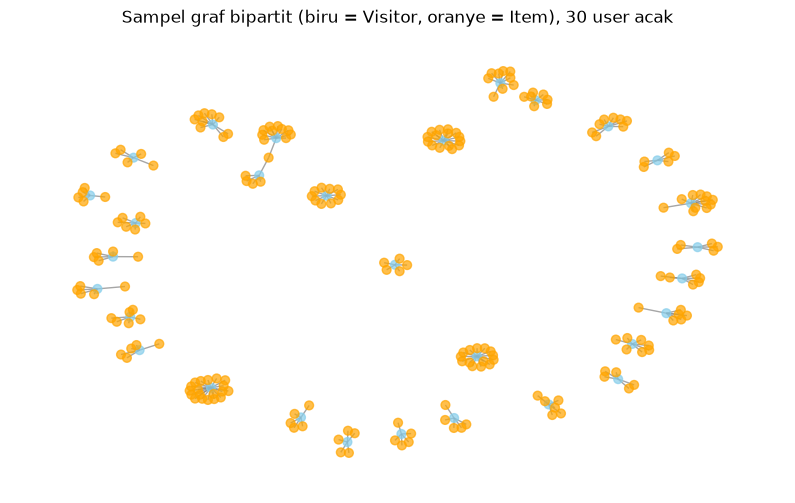

In [17]:
rng = np.random.default_rng(42)

deg_u = np.asarray((M_user > 0).sum(axis=1)).ravel()
kandidat = np.where((deg_u >= 5) & (deg_u <= 30))[0]     # user dengan 5-30 item
pick = rng.choice(kandidat, size=min(30, len(kandidat)), replace=False)

sub = M_user[pick]
sub = sub[:, np.asarray((sub > 0).sum(axis=0)).ravel() > 0]   
G = nx.bipartite.from_biadjacency_matrix((sub > 0).astype(int))
print(f"Sampel: {sub.shape[0]} user, {sub.shape[1]} item, {G.number_of_edges()} edge")

n_u = sub.shape[0]
colors = ['skyblue' if n < n_u else 'orange' for n in G.nodes]

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42, iterations=50)
nx.draw_networkx(G, pos, node_color=colors, node_size=40,
                 with_labels=False, edge_color='gray', alpha=0.7)
plt.title("Sampel graf bipartit (biru = Visitor, oranye = Item), 30 user acak")
plt.axis('off')
plt.show()

=== VSM USER ===
Dimensi vektor (item)   : 91,927
Jumlah vektor (user)    : 210,737
Shape                      : (210737, 91927)
Non-zero                   : 294,837
Sparsity                   : 99.9985%
Degree min/median/mean/max : 1 / 1 / 1.40 / 760
Baris dengan 1 interaksi   : 83.2%


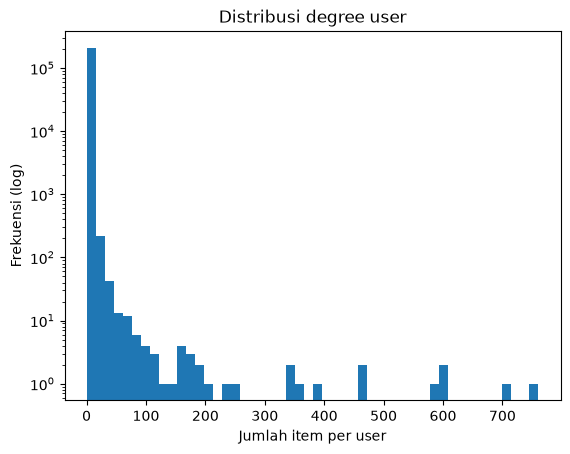

In [18]:
def karakteristik(M, baris, kolom):
    deg = np.asarray((M > 0).sum(axis=1)).ravel()     
    n, m = M.shape
    print(f"Dimensi vektor ({kolom})   : {m:,}")
    print(f"Jumlah vektor ({baris})    : {n:,}")
    print(f"Shape                      : {M.shape}")
    print(f"Non-zero                   : {M.nnz:,}")
    print(f"Sparsity                   : {(1 - M.nnz/(n*m))*100:.4f}%")
    print(f"Degree min/median/mean/max : {deg.min()} / {np.median(deg):.0f} / {deg.mean():.2f} / {deg.max()}")
    print(f"Baris dengan 1 interaksi   : {(deg==1).mean()*100:.1f}%")
    return deg

print("=== VSM USER ===")
deg_u = karakteristik(M_user, "user", "item")

plt.hist(deg_u, bins=50, log=True)
plt.xlabel("Jumlah item per user"); plt.ylabel("Frekuensi (log)")
plt.title("Distribusi degree user"); plt.show()

=== VSM ITEM ===
Dimensi vektor (user)   : 210,737
Jumlah vektor (item)    : 91,927
Shape                      : (91927, 210737)
Non-zero                   : 294,837
Sparsity                   : 99.9985%
Degree min/median/mean/max : 1 / 1 / 3.21 / 1570
Baris dengan 1 interaksi   : 53.0%


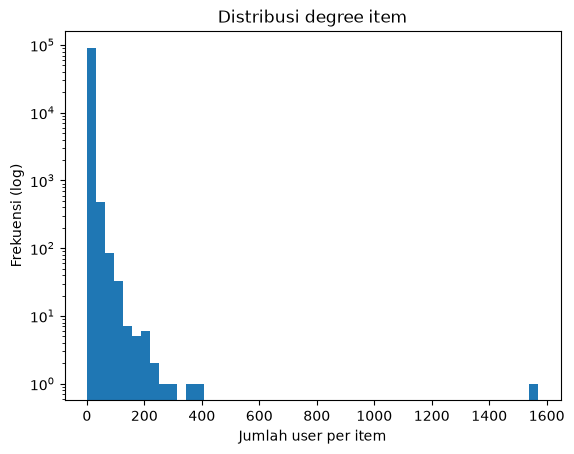

In [20]:
print("=== VSM ITEM ===")
deg_i = karakteristik(M_item, "item", "user")

plt.hist(deg_i, bins=50, log=True)
plt.xlabel("Jumlah user per item"); plt.ylabel("Frekuensi (log)")
plt.title("Distribusi degree item"); plt.show()

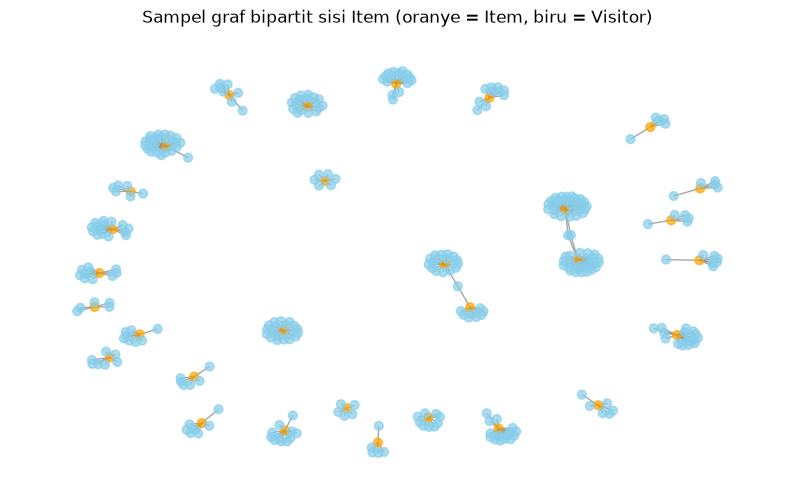

In [21]:
rng = np.random.default_rng(42)
kandidat = np.where((deg_i >= 5) & (deg_i <= 30))[0]
pick = rng.choice(kandidat, size=min(30, len(kandidat)), replace=False)

sub = M_item[pick]
sub = sub[:, np.asarray((sub > 0).sum(axis=0)).ravel() > 0]
G_i = nx.bipartite.from_biadjacency_matrix((sub > 0).astype(int))

n_i = sub.shape[0]
colors = ['orange' if n < n_i else 'skyblue' for n in G_i.nodes]
plt.figure(figsize=(10, 6))
nx.draw_networkx(G_i, nx.spring_layout(G_i, seed=42, iterations=50),
                 node_color=colors, node_size=40, with_labels=False,
                 edge_color='gray', alpha=0.7)
plt.title("Sampel graf bipartit sisi Item (oranye = Item, biru = Visitor)")
plt.axis('off'); plt.show()

VSM User dan VSM Item merupakan dua proyeksi matriks yang saling berpasangan (transpose) dari satu graf bipartit yang sama, dengan shape masing-masing (210.737, 91.927) dan (91.927, 210.737). Memiliki nilai sparsity ekstrem sebesar 99,9985% dengan 294.837 elemen aktif. Distribusi derajatnya didominasi oleh transaksi tunggal di mana 83,2% User dan 53,0% Item hanya memiliki 1 interaksi (median degree = 1). Meskipun sangat senggang, terdapat beberapa simpul hub populer dengan derajat maksimum mencapai 760 untuk User dan 1.570 untuk Item. Pada visualisasi NetworkX, struktur ini akan membentuk pola menyerupai bintang (star-like subgraphs) yang dipenuhi simpul-simpul gantung berderajat 1 serta beberapa pusat klaster padat di sekeliling produk yang paling populer.

### Nomor 6

Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [22]:
B = (M_user > 0).astype(np.int32)
deg_u = np.asarray(B.sum(axis=1)).ravel().astype(np.int64)   # item per user
deg_i = np.asarray(B.sum(axis=0)).ravel().astype(np.int64)   # user per item

n_u, n_i = B.shape

edge_uu = int((deg_i * (deg_i - 1) // 2).sum())   # dua user berbagi 1 item
edge_ii = int((deg_u * (deg_u - 1) // 2).sum())   # dua item dilihat 1 user

hasil = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Simpul": [n_u, n_i],
    "Maks. pasangan (n(n-1)/2)": [n_u*(n_u-1)//2, n_i*(n_i-1)//2],
    "Batas atas edge": [edge_uu, edge_ii],
})
hasil["Densitas (%)"] = hasil["Batas atas edge"] / hasil["Maks. pasangan (n(n-1)/2)"] * 100
print(hasil.to_string(index=False))

 Proyeksi  Simpul  Maks. pasangan (n(n-1)/2)  Batas atas edge  Densitas (%)
User-User  210737                22204936216          3517414      0.015841
Item-Item   91927                 4225240701          2129261      0.050394


In [23]:
S = (B.T @ B).tocsr()
S.setdiag(0); S.eliminate_zeros()
print("Item-item: shape", S.shape, "nnz", S.nnz)

Item-item: shape (91927, 91927) nnz 4086102


In [24]:
S_uu = (B @ B.T).tocsr()
S_uu.setdiag(0); S_uu.eliminate_zeros()
S_ii = S   # item-item yang sudah dihitung

def ringkas(S, nama):
    deg = np.diff(S.indptr)
    print(f"{nama}: simpul={S.shape[0]:,}, edge unik={S.nnz//2:,}, "
          f"rata2 degree={deg.mean():.2f}, terisolasi={(deg==0).mean()*100:.1f}%")

ringkas(S_uu, "User-User")
ringkas(S_ii, "Item-Item")

User-User: simpul=210,737, edge unik=3,459,008, rata2 degree=32.83, terisolasi=16.2%
Item-Item: simpul=91,927, edge unik=2,043,051, rata2 degree=44.45, terisolasi=49.8%


Proyeksi item–item dipilih karena lebih efisien dan lebih informatif, dengan satu catatan cakupan. (1) Efisiensi: simpul 56% lebih sedikit (91.927 vs 210.737) dan edge 41% lebih sedikit (2,04 juta vs 3,46 juta), sehingga perhitungan similarity lebih murah. (2) Kualitas informasi: pada simpul yang tidak terisolasi, rata-rata degree item ≈89 berbanding ≈39 pada user, dan densitasnya sekitar 9 kali lipat. Artinya tiap item punya banyak kandidat yang mirip, sedangkan kesamaan antar-user tipis karena 83,2% user hanya punya satu interaksi. (3) Stabilitas: relasi antar-item lebih stabil dan bisa dihitung sekali. Kelemahan: 49,8% item terisolasi (tidak punya tetangga) sehingga tidak bisa direkomendasikan lewat kemiripan, sedangkan di user–user hanya 16,2%. Selain itu, user outlier (760 item) menggelembungkan jumlah pasangan di item–item, sehingga perlu ambang degree atau bobot.

### Nomor 7

Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python.

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!

pakai P1

In [25]:
query_vsm_train = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period = 'P1'
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1
                        WHEN 'ADDED_TO_CART' THEN 3
                        WHEN 'BOUGHT' THEN 5 END) AS weight
"""

In [ ]:
import numpy as np, pandas as pd, scipy.sparse as sp

with driver.session(database='grafuts') as s:
    df_train = pd.DataFrame(s.run(query_vsm_train).data())
print(df_train.shape)

u_cat = df_train['visitor'].astype('category')
i_cat = df_train['item'].astype('category')
item_ids = i_cat.cat.categories.to_numpy()         

M_train = sp.csr_matrix(
    (df_train['weight'], (u_cat.cat.codes, i_cat.cat.codes)),
    shape=(len(u_cat.cat.categories), len(item_ids)))
M_item_tr = M_train.T.tocsr()                        # Item dot User
print("VSM Item P1:", M_item_tr.shape, "nnz =", M_item_tr.nnz)

(198318, 3)
VSM Item P1: (73348, 142829) nnz = 198318


similarity py

In [30]:
norms = np.sqrt(np.asarray(M_item_tr.multiply(M_item_tr).sum(axis=1)).ravel())
Mn = sp.diags(1.0 / norms) @ M_item_tr               # normalisasi baris (L2)

S_train = (Mn @ Mn.T).tocsr()                        # cosine similarity item-item
S_train.setdiag(0); S_train.eliminate_zeros()
print("Proyeksi item-item P1:", S_train.shape, "nnz =", S_train.nnz)

Proyeksi item-item P1: (73348, 73348) nnz = 2262734


item acuan

In [ ]:
rng = np.random.default_rng(42)
deg = np.diff(S_train.indptr)
deg_users = np.diff(M_item_tr.indptr)
ref_idx = int(rng.choice(np.where((deg >= 5) & (deg_users >= 5))[0]))
ref_item = int(item_ids[ref_idx])

row = S_train.getrow(ref_idx)
order = np.lexsort((item_ids[row.indices], -np.round(row.data, 12)))[:5]
top5 = [{"item": int(item_ids[row.indices[j]]), "score": float(row.data[j])} for j in order]

print("Item acuan:", ref_item)
print(pd.DataFrame(top5))

Item acuan: 44319
     item     score
0   16899  0.603023
1  164348  0.603023
2  409725  0.603023
3  202077  0.348155
4  333904  0.311400


before after

In [32]:
def n_similar():
    with driver.session(database='grafuts') as s:
        return s.run("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n").single()["n"]

print("SIMILAR_TO sebelum:", n_similar())          # harusnya 0

SIMILAR_TO sebelum: 0


perhitungan similarity dengan cypher

In [ ]:
with driver.session(database='grafuts') as s:
    s.run("MATCH (:Item)-[s:SIMILAR_TO]->(:Item) DELETE s")   # buang relasi lama
    s.run("""
        MATCH (a:Item {itemId: $ref})
        UNWIND $rows AS row
        MATCH (b:Item {itemId: row.item})
        MERGE (a)-[s:SIMILAR_TO]->(b)
        SET s.score = row.score, s.metric = 'cosine-weighted', s.period = 'P1'
    """, ref=ref_item, rows=top5)

q_show = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS similarity, s.metric AS metrik
ORDER BY s.score DESC, b.itemId
"""
with driver.session(database='grafuts') as s:
    df_show = pd.DataFrame(s.run(q_show, ref=ref_item).data())
print("SIMILAR_TO sesudah:", n_similar())   # harus 5
df_show

SIMILAR_TO sesudah: 5


,acuan,mirip,similarity,metrik
0,44319,16899,0.603023,cosine-weighted
1,44319,164348,0.603023,cosine-weighted
2,44319,409725,0.603023,cosine-weighted
3,44319,202077,0.348155,cosine-weighted
4,44319,333904,0.311400,cosine-weighted


7a

Cypher untuk mengambil Top 5:

MATCH (a:Item {itemId: $ref})
        UNWIND $rows AS row
        MATCH (b:Item {itemId: row.item})
        MERGE (a)-[s:SIMILAR_TO]->(b)
        SET s.score = row.score, s.metric = 'cosine-weighted', s.period = 'P1'


7b

hasil cosine similarity sudah tertuliskan 

### Nomor 8

Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

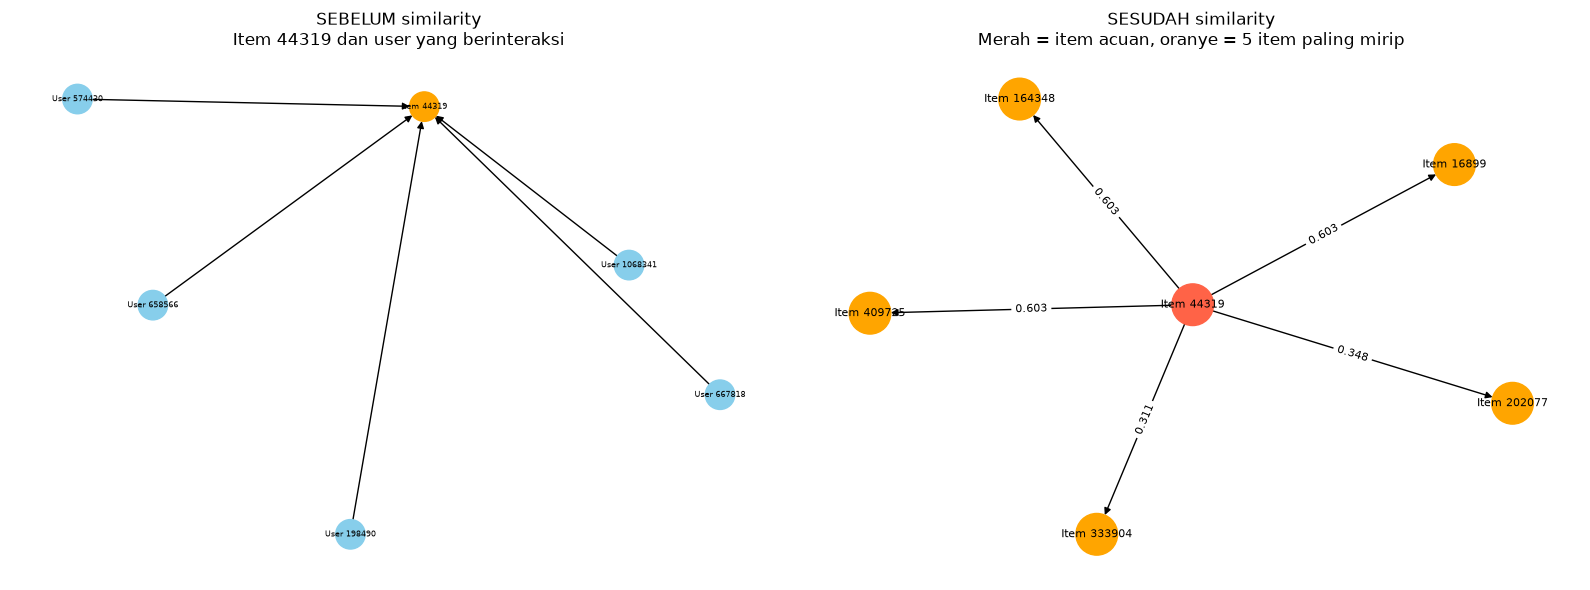

In [53]:
import networkx as nx
import matplotlib.pyplot as plt

DB = 'grafuts'

q_before = """
MATCH (v:Visitor)-[r]->(a:Item {itemId: $ref})
RETURN v.visitorId AS visitor, type(r) AS relasi
LIMIT 5
"""
q_after = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS mirip, s.score AS score
"""

with driver.session(database=DB) as s:
    rows_b = s.run(q_before, ref=ref_item).data()
    rows_a = s.run(q_after, ref=ref_item).data()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#sebelum
G1 = nx.DiGraph()
G1.add_node(f"Item {ref_item}")
for r in rows_b:
    G1.add_edge(f"User {r['visitor']}", f"Item {ref_item}", label=r['relasi'])
c1 = ['orange' if n.startswith('Item') else 'skyblue' for n in G1.nodes]
pos1 = nx.spring_layout(G1, seed=42)
nx.draw_networkx(G1, pos1, ax=axes[0], node_color=c1, node_size=450,
                 font_size=6, arrows=True)
axes[0].set_title(f"SEBELUM similarity\nItem {ref_item} dan user yang berinteraksi")
axes[0].axis('off')

#setelah
G2 = nx.DiGraph()
G2.add_node(f"Item {ref_item}")
for r in rows_a:
    G2.add_edge(f"Item {ref_item}", f"Item {r['mirip']}", label=f"{r['score']:.3f}")

c2 = ['tomato' if n == f"Item {ref_item}" else 'orange' for n in G2.nodes]
pos2 = nx.spring_layout(G2, seed=42)
nx.draw_networkx(G2, pos2, ax=axes[1], node_color=c2, node_size=900,
                 font_size=8, arrows=True)
nx.draw_networkx_edge_labels(G2, pos2, ax=axes[1],
                             edge_labels=nx.get_edge_attributes(G2, 'label'), font_size=8)
axes[1].set_title("SESUDAH similarity\nMerah = item acuan, oranye = 5 item paling mirip")
axes[1].axis('off')

plt.tight_layout()
plt.show()

Cypher sebelum similarity:

MATCH (v:Visitor)-[r]->(a:Item {itemId: $ref})
RETURN v.visitorId AS visitor, type(r) AS relasi
LIMIT 5

Cypher setelah similarity:

MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS mirip, s.score AS score

Hasil:

Kondisi Sebelum Similarity (Graf Kiri):
Memperlihatkan jaringan bipartit di mana Item acuan (Item 44319 berwarna oranye) hanya terhubung secara pasif oleh garis masuk (in-degree) dari simpul-simpul User/Visitor (skyblue) yang pernah berinteraksi darinya. Belum ada keterhubungan langsung antar sesama Item.

Kondisi Sesudah Similarity (Graf Kanan):
Memperlihatkan jaringan unipartit Item-to-Item. Item acuan (Item 44319 berwarna merah) kini terhubung langsung (out-degree) ke 5 Item lain (oranye) melalui relasi :SIMILAR_TO, lengkap dengan bobot nilai cosine similarity pada setiap garisnya

## 2.2 Analytic

### Nomor 1

Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

pakai P2

In [38]:
query_vsm_test = query_vsm_train.replace("'P1'", "'P2'")

with driver.session(database='grafuts') as s:
    df_test = pd.DataFrame(s.run(query_vsm_test).data())
print("P2:", df_test.shape)

user_ids = u_cat.cat.categories.to_numpy()
uidx = {int(u): k for k, u in enumerate(user_ids)}      

t = df_test[df_test['item'].isin(item_ids) & df_test['visitor'].isin(user_ids)][['visitor', 'item']].drop_duplicates()
m = t.merge(df_train[['visitor', 'item']], how='left', on=['visitor', 'item'], indicator=True)
t = m[m['_merge'] == 'left_only'][['visitor', 'item']]
gt_all = {int(u): set(map(int, g)) for u, g in t.groupby('visitor')['item']}
print("User dengan ground truth:", len(gt_all))

P2: (98647, 3)
User dengan ground truth: 2268


Ground truth adalah item yang diinteraksi user di P2. Item yang sudah ada di P1 dikeluarkan, dan item yang tidak ada di katalog P1 juga dikeluarkan karena tidak punya similarity (cold-item). Pemilihan user acak: default_rng(42) mengacak daftar user yang memenuhi syarat. User pertama yang punya ≥5 kandidat rekomendasi dipakai.

skrip knn

In [39]:
def recommend(u_idx, k=5, n_rec=5):
    row = M_train.getrow(u_idx)
    seen = set(row.indices)
    scores = {}
    for i, w in zip(row.indices, row.data):
        s = S_train.getrow(i)
        order = np.lexsort((s.indices, -s.data))[:k]      # k tetangga
        for p in order:
            j = int(s.indices[p])
            if j in seen:
                continue
            scores[j] = scores.get(j, 0.0) + w * s.data[p]
    ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:n_rec]
    return [(int(item_ids[j]), float(sc)) for j, sc in ranked]

# pilih user acak
rng = np.random.default_rng(42)
for u in rng.permutation(sorted(gt_all)):
    u = int(u)
    rec = recommend(uidx[u], k=5, n_rec=5)
    if len(rec) >= 5:
        break

print("User terpilih :", u)
print("Item P1 user  :", [int(item_ids[j]) for j in M_train.getrow(uidx[u]).indices])
print("Ground truth  :", gt_all[u])
print(pd.DataFrame(rec, columns=["item", "skor"]).assign(peringkat=range(1, 6)))

User terpilih : 1102269
Item P1 user  : [268883, 283916]
Ground truth  : {420960}
    item      skor  peringkat
0   1956  4.057513          1
1  11623  4.057513          2
2  13896  4.057513          3
3  25404  4.057513          4
4  40866  4.057513          5


item yang diiklankan

In [40]:
rec_items = [it for it, _ in rec]
print("3 item yang diiklankan (k=5):", rec_items[:3])

3 item yang diiklankan (k=5): [1956, 11623, 13896]


### Nomor 2

Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

hitung Hit@5 dan NDCG@5

In [41]:
def hit_at_n(rec_items, gt, n=5):
    return int(any(it in gt for it in rec_items[:n]))

def ndcg_at_n(rec_items, gt, n=5):
    dcg = sum(1 / np.log2(r + 2) for r, it in enumerate(rec_items[:n]) if it in gt)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(gt), n)))
    return dcg / idcg if idcg > 0 else 0.0

gt = gt_all[u]
print(f"Hit@5  = {hit_at_n(rec_items, gt, 5)}")
print(f"NDCG@5 = {ndcg_at_n(rec_items, gt, 5):.4f}")

print(f"Hit@3  = {hit_at_n(rec_items, gt, 3)} | NDCG@3 = {ndcg_at_n(rec_items, gt, 3):.4f}")

Hit@5  = 0
NDCG@5 = 0.0000
Hit@3  = 0 | NDCG@3 = 0.0000


Untuk satu user, Hit@5 hanya bernilai 0 atau 1, jadi sangat tidak stabil. Dengan data sparse seperti ini, kemungkinan besar hasilnya 0.

In [42]:
rng = np.random.default_rng(42)
sample = rng.permutation(sorted(gt_all))[:1000]
hs, ns = [], []
for uu in sample:
    uu = int(uu)
    r = [it for it, _ in recommend(uidx[uu], k=5, n_rec=5)]
    hs.append(hit_at_n(r, gt_all[uu])); ns.append(ndcg_at_n(r, gt_all[uu]))
print(f"{len(sample)} user | Hit@5 rata-rata = {np.mean(hs):.4f} | NDCG@5 rata-rata = {np.mean(ns):.4f}")

1000 user | Hit@5 rata-rata = 0.0370 | NDCG@5 rata-rata = 0.0174


Hit@5 sebesar 0.0370 (3,70%): Menunjukkan bahwa dari 1.000 sampel user, sebanyak 3,7% pengguna berhasil mendapatkan minimal 1 rekomendasi item yang sesuai (relevant item/ground truth) di dalam daftar Top-5 rekomendasi.

NDCG@5 sebesar 0.0174: Mengukur presisi sekaligus urutan (ranking quality) dari item relevan. Nilai ini mencerminkan bahwa selain item relevan berhasil direkomendasikan, posisinya cenderung berada di urutan atas daftar Top-5. Nilai metrik yang relatif kecil ini merupakan karakteristik umum pada dataset e-commerce dengan sparsity tinggi (99,99%)